# 01 · Exploración y limpieza de los datos

Objetivo: justificar las decisiones de preprocesado del pipeline (`oilcast build`):

1. Calendario del Brent y valores repetidos del CSV original.
2. Huecos por festivos distintos en cada mercado.
3. *Outliers*: WTI negativo (abril 2020) y extremos del Brent (2008, 2020, 2022, 2026).
4. Estacionariedad y elección de variables de entrada.

Todo el código de transformación vive en el paquete `oilcast`; aquí solo se importa y se inspecciona.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oilcast.config import load_config
from oilcast.data.dataset import load_dataset, load_raw
from oilcast.features.engineering import FEATURE_DESCRIPTIONS, compute_features
from oilcast.features.windows import Scaler
from oilcast.paths import get_paths
from oilcast.utils import read_json

cfg = load_config()
paths = get_paths(cfg)
plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True, "grid.alpha": 0.3})

## 1. Series en bruto y cobertura

`oilcast download` guarda cada fuente **sin rellenar** en `data/raw/` (una fila por día publicado).

In [2]:
names = [
    *cfg["data"]["fred"].values(),
    *cfg["data"]["yahoo_ohlcv"].values(),
    *cfg["data"]["yahoo_close"].values(),
]
rows = []
for n in names:
    raw = load_raw(paths, n)
    col = n if n in raw.columns else "close"
    s = raw[col].dropna()
    rows.append(
        {
            "serie": n,
            "desde": s.index.min().date(),
            "hasta": s.index.max().date(),
            "observaciones": len(s),
        }
    )
print("Cesta OPEP disponible:", (paths.raw / "opec.csv").exists())
pd.DataFrame(rows).set_index("serie")

Cesta OPEP disponible: False


,desde,hasta,observaciones
serie,,,
brent,2000-01-04,2026-11-03,6501
wti,2000-01-04,2026-11-03,6352
gas,2000-01-10,2026-11-11,5433
ecb_rate,2000-01-01,2026-11-12,9813
usd_per_eur,2000-01-03,2026-11-06,6732
cny_per_usd,2000-01-03,2026-11-06,6733
vix,2000-01-03,2026-11-11,6790
brent_fut,2007-07-30,2026-11-12,4803
wti_fut,2000-08-23,2026-11-12,6585


La cesta de la OPEP no se ha podido descargar: la web oficial (`opec.org`) devuelve **403**
a clientes automáticos (protección anti-bots). El pipeline la trata como opcional y funciona sin ella.

## 2. El problema del CSV original: precios del Brent «congelados»

El script proporcionado (`scripts/download_data.py`) aplica `ffill()` a **todas** las columnas,
incluido el objetivo, y conserva los días en que el Brent no cotiza. Resultado: días festivos y la
cola final (el Brent spot se publica con varios días de retraso) aparecen con el precio repetido.

In [3]:
orig = pd.read_csv(paths.root / "data" / "petroleo_dataset.csv", index_col=0, parse_dates=True)
brent_raw = load_raw(paths, "brent")["brent"].dropna()
unchanged = (orig["brent"].diff() == 0).sum()
not_real = ~orig.index.isin(brent_raw.index)
print(f"Filas del CSV original: {len(orig)}; días con el Brent sin cambio: {unchanged}")
print(f"Filas del CSV sin dato real de Brent ese día: {not_real.sum()}")
print(f"Último dato real del Brent en FRED: {brent_raw.index.max().date()}")
orig.loc[orig.index > "2026-10-28", ["brent", "wti", "brent_fut_Close"]]

Filas del CSV original: 7008; días con el Brent sin cambio: 577
Filas del CSV sin dato real de Brent ese día: 507
Último dato real del Brent en FRED: 2026-11-03


,brent,wti,brent_fut_Close
Date,,,
2026-10-29,115.28,105.51,114.879997
2026-10-30,120.15,107.56,117.639999
2026-11-02,107.39,100.06,104.769997
2026-11-03,107.03,99.64,103.599998
2026-11-04,107.03,99.64,94.620003
2026-11-05,107.03,99.64,98.290001
2026-11-06,107.03,99.64,98.320000
2026-11-09,107.03,99.64,92.570000
2026-11-10,107.03,99.64,91.489998


Entrenar con esos días añade pares (entrada, objetivo) falsos: el «precio de mañana» sería igual
al de hoy por construcción, lo que favorece artificialmente al modelo ingenuo y contamina las
métricas. **Decisión**: el dataset de modelado usa el **calendario real del Brent** (solo días en
los que la EIA publica precio) y solo las *demás* series se rellenan con su último valor
disponible en esa fecha (nunca hacia atrás).

In [4]:
df = load_dataset(paths)
log = read_json(paths.cleaning_log)
print(f"Dataset de modelado: {len(df)} filas, {df.index[0].date()} -> {df.index[-1].date()}")
missing = pd.bdate_range("2010-01-01", "2025-12-31").difference(df.index)
print(f"Días laborables sin Brent (2010-2025): {len(missing)} (~{len(missing) / 16:.1f} al año)")
pd.Series(missing.strftime("%d-%m")).value_counts().head(8).rename("veces")

Dataset de modelado: 6501 filas, 2000-01-04 -> 2026-11-03
Días laborables sin Brent (2010-2025): 127 (~7.9 al año)


01-01    11
25-12    11
26-12     8
04-07     4
27-12     4
02-04     3
02-01     3
27-05     3
Name: veces, dtype: int64

Los días sin Brent son esencialmente los festivos bancarios del Reino Unido (Año Nuevo, Viernes
Santo, Lunes de Pascua, *bank holidays* de mayo y agosto, Navidad y San Esteban). La app usa ese
mismo calendario para fechar los horizontes de 5, 63 y 252 días hábiles.

## 3. Huecos de las variables externas

Cada mercado tiene su calendario. Al alinear con el Brent, el hueco se rellena con el último valor
publicado **hasta esa fecha**. Antes de su primera observación, la serie queda vacía:

In [5]:
pd.DataFrame(
    {
        "primer dato": log["first_valid"],
        "filas vacías al inicio": pd.Series(log["missing_before_first_valid"]),
    }
).fillna(0)

,primer dato,filas vacías al inicio
brent,2000-01-04,0.0
brent_fut_close,2007-07-30,1629.0
brent_fut_high,2007-07-30,1629.0
brent_fut_low,2007-07-30,1629.0
brent_fut_open,2007-07-30,1629.0
brent_fut_volume,2007-07-30,1629.0
cny_per_usd,2000-01-04,0.0
copper,2000-08-30,137.0
dxy,2000-01-04,0.0
ecb_rate,2000-01-04,0.0


- Futuros WTI (`CL=F`), cobre y oro empiezan a finales de agosto de 2000 → la muestra de modelado
  empieza cuando existen todas las variables y sus ventanas móviles (julio de 2001).
- Futuros del Brent (`BZ=F`) solo desde 2007-07-30 → **no se usan como entrada** (habría que
  descartar 7 años de historia o inventar 1.600 valores). La información de la curva de futuros
  entra a través de la base WTI spot – futuro, disponible desde 2000.

## 4. Outliers

### 4.1 WTI negativo (20 de abril de 2020)

{'wti': [['2020-04-20', -36.98]], 'wti_fut_open': [['2020-04-21', -14.0]], 'wti_fut_low': [['2020-04-20', -40.31999969482422], ['2020-04-21', -16.739999771118164]], 'wti_fut_close': [['2020-04-20', -37.630001068115234]], 'brent_fut_volume': ['14 días con volumen 0 -> NaN'], 'wti_fut_volume': ['13 días con volumen 0 -> NaN']}


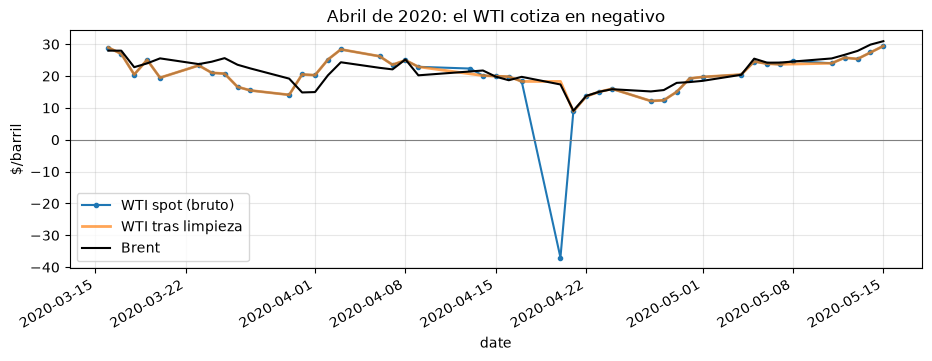

In [6]:
print(log["non_positive_or_zero_volume"])
wti_raw = load_raw(paths, "wti")["wti"]
fig, ax = plt.subplots()
wti_raw.loc["2020-03-15":"2020-05-15"].plot(ax=ax, label="WTI spot (bruto)", marker=".")
df["wti"].loc["2020-03-15":"2020-05-15"].plot(ax=ax, label="WTI tras limpieza", lw=2, alpha=0.7)
df["brent"].loc["2020-03-15":"2020-05-15"].plot(ax=ax, label="Brent", color="black")
ax.axhline(0, color="grey", lw=0.8)
ax.legend()
ax.set_title("Abril de 2020: el WTI cotiza en negativo")
ax.set_ylabel("$/barril");

Un precio negativo no admite logaritmo: la rentabilidad logarítmica sería indefinida. Es un
episodio real (contrato de mayo a punto de vencer con los depósitos de Cushing llenos), pero como
**variable de entrada** se trata como dato no válido: se marca como ausente y se usa el último valor
disponible. Lo mismo para los futuros con precio ≤ 0 y los ~27 días con volumen 0. El objetivo
(Brent) nunca tuvo precio negativo.

### 4.2 Extremos del Brent: se conservan

Máximo 2008           2008-07-03 · 143.95 $
Mínimo crisis 2008     2008-12-26 · 33.73 $
Mínimo 2016            2016-01-20 · 26.01 $
Mínimo pandemia         2020-04-21 · 9.12 $
Máximo 2022           2022-03-08 · 133.18 $
Máximo 2026           2026-04-07 · 138.21 $
dtype: str

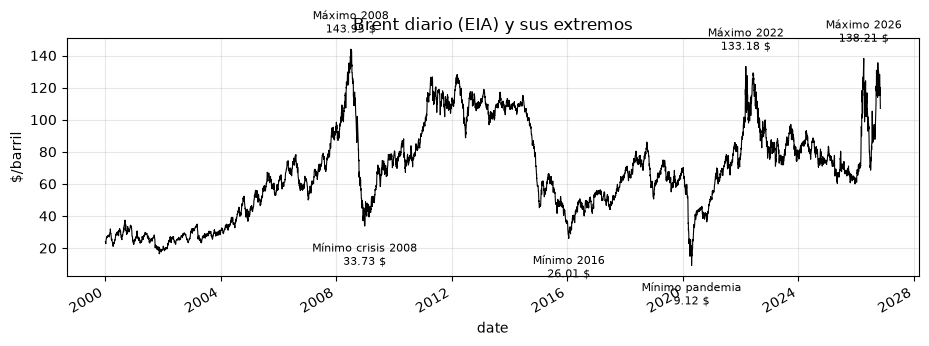

In [7]:
b = df["brent"]
ext = {
    "Máximo 2008": b["2008"].idxmax(),
    "Mínimo crisis 2008": b["2008-09":"2009-06"].idxmin(),
    "Mínimo 2016": b["2015-06":"2016-06"].idxmin(),
    "Mínimo pandemia": b["2020"].idxmin(),
    "Máximo 2022": b["2022"].idxmax(),
    "Máximo 2026": b["2026"].idxmax(),
}
fig, ax = plt.subplots()
b.plot(ax=ax, color="black", lw=0.8)
for k, d in ext.items():
    ax.annotate(
        f"{k}\n{b[d]:.2f} $",
        (d, b[d]),
        fontsize=8,
        ha="center",
        xytext=(0, 12 if "Máx" in k else -28),
        textcoords="offset points",
    )
ax.set_title("Brent diario (EIA) y sus extremos")
ax.set_ylabel("$/barril")
pd.Series({k: f"{d.date()} · {b[d]:.2f} $" for k, d in ext.items()})

Son precios **reales**, no errores: eliminarlos sería ocultar precisamente los episodios que más
importan a un usuario. En lugar de «limpiarlos» del objetivo:

- se modelan **rentabilidades** (log P[t+h]/P[t]) y no niveles, de modo que un precio de 140 $ y uno
  de 40 $ producen entradas comparables;
- las **entradas** se recortan a los percentiles 0,5 %-99,5 % y se estandarizan con parámetros
  ajustados **solo con el tramo de entrenamiento** de cada partición;
- la pérdida pinball (de cuantiles) es robusta a valores extremos del objetivo, a diferencia del MSE.

In [8]:
r = np.log(b).diff().dropna()
print(
    f"Rentabilidad diaria del Brent: media {r.mean():.5f}, desv. {r.std():.4f}, "
    f"curtosis {r.kurt():.1f} (normal = 0)"
)
print("Días con |rentabilidad| > 10 %:", (r.abs() > 0.10).sum())
r.sort_values().iloc[[0, 1, 2, -3, -2, -1]]

Rentabilidad diaria del Brent: media 0.00023, desv. 0.0274, curtosis 63.8 (normal = 0)
Días con |rentabilidad| > 10 %: 43


date
2020-04-21   -0.643699
2020-03-31   -0.256389
2020-03-09   -0.255175
2020-05-05    0.221574
2020-04-02    0.301613
2020-04-22    0.412023
Name: brent, dtype: float64

## 5. Estacionariedad y variables de entrada

El precio en nivel no es estacionario (su media y su varianza cambian con el tiempo); las
rentabilidades sí lo son aproximadamente, aunque con volatilidad variable (agrupamiento de
volatilidad), que se incorpora como variable explícita.

Autocorrelación lag 1 -> log precio: 0.9982 | rentabilidades: -0.0097


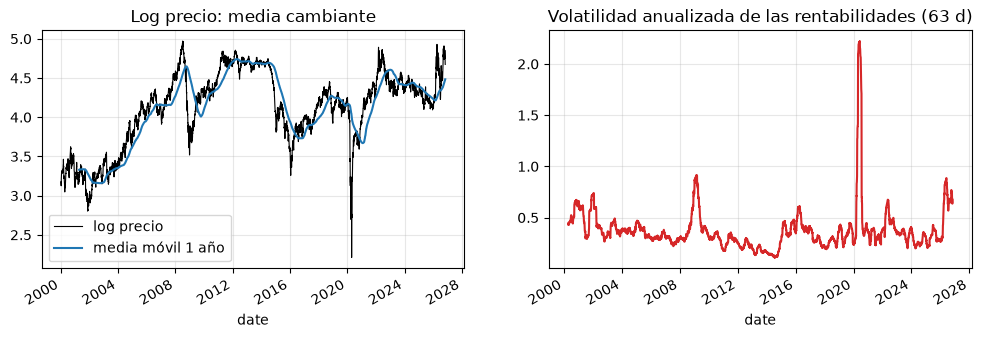

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
lp = np.log(b)
lp.plot(ax=axes[0], color="black", lw=0.8, label="log precio")
lp.rolling(252).mean().plot(ax=axes[0], label="media móvil 1 año")
axes[0].set_title("Log precio: media cambiante")
axes[0].legend()
r.rolling(63).std().mul(np.sqrt(252)).plot(ax=axes[1], color="tab:red")
axes[1].set_title("Volatilidad anualizada de las rentabilidades (63 d)")
print(
    "Autocorrelación lag 1 -> log precio:",
    round(lp.autocorr(1), 4),
    "| rentabilidades:",
    round(r.autocorr(1), 4),
)

Variables de entrada (todas calculadas solo con información disponible al cierre del día):

In [10]:
feats = compute_features(df, cfg)
pd.DataFrame(
    {
        "descripción": FEATURE_DESCRIPTIONS,
        "primer dato": feats.apply(lambda s: s.first_valid_index().date()),
    }
)

,descripción,primer dato
r_brent,Rentabilidad logarítmica diaria del Brent,2000-01-05
r_wti,Rentabilidad logarítmica diaria del WTI spot,2000-01-05
r_gas,Rentabilidad logarítmica diaria del gas natura...,2000-01-11
r_gold,Rentabilidad logarítmica diaria del oro,2000-09-01
r_copper,Rentabilidad logarítmica diaria del cobre,2000-09-01
r_dxy,Rentabilidad logarítmica diaria del índice dólar,2000-01-05
r_eurusd,Rentabilidad logarítmica diaria del USD/EUR,2000-01-05
r_cny,Rentabilidad logarítmica diaria del CNY/USD,2000-01-05
log_vix,Logaritmo del VIX (nivel de aversión al riesgo),2000-01-04
ecb_rate,Tipo de la facilidad de depósito del BCE (nive...,2000-01-04


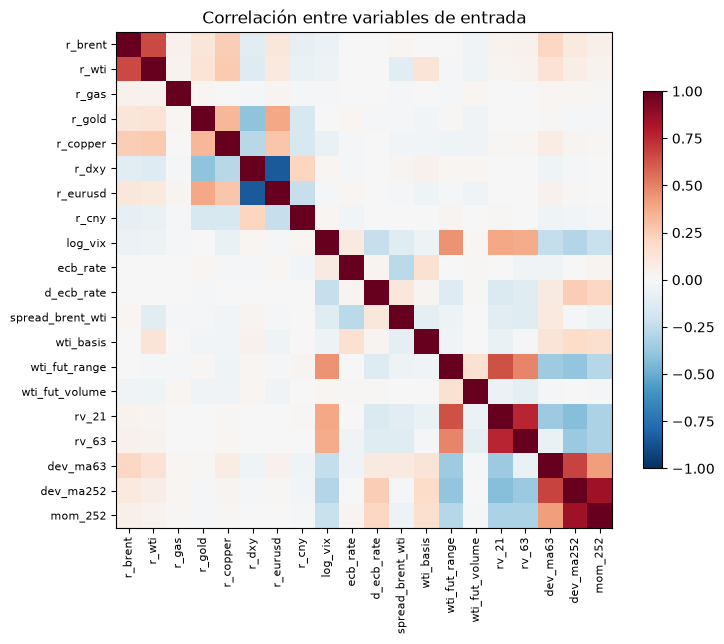

In [11]:
corr = feats.loc["2001-07":].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("Correlación entre variables de entrada")
ax.grid(False);

## 6. Escalado ajustado solo con entrenamiento

Ejemplo con la partición de test (entrenamiento hasta 2021): los umbrales de recorte y la
media/desviación salen solo de filas anteriores al último origen de entrenamiento; el periodo de
test se transforma con esos mismos parámetros.

In [12]:
train_rows = np.flatnonzero(feats.index < "2021-01-01")
sc = Scaler.fit(feats.to_numpy(np.float32), train_rows, tuple(cfg["features"]["clip_quantiles"]))
z = pd.DataFrame(sc.transform(feats.to_numpy(np.float32)), index=feats.index, columns=feats.columns)
pd.DataFrame(
    {
        "media train": z.loc[:"2020"].mean(),
        "desv. train": z.loc[:"2020"].std(),
        "media test": z.loc["2022":].mean(),
        "desv. test": z.loc["2022":].std(),
    }
).round(2)

,media train,desv. train,media test,desv. test
r_brent,0.0,1.00,0.00,1.12
r_wti,-0.0,1.00,0.00,1.03
r_gas,0.0,1.00,-0.01,1.62
r_gold,0.0,0.99,0.03,1.06
r_copper,0.0,0.99,0.01,0.93
r_dxy,0.0,1.00,0.02,0.90
r_eurusd,-0.0,1.00,-0.01,0.79
r_cny,0.0,1.00,0.08,1.58
log_vix,-0.0,1.00,0.02,0.68
ecb_rate,-0.0,1.00,1.16,1.05


En test las medias y desviaciones no son exactamente 0 y 1 (2022 y 2026 fueron años de
volatilidad muy alta), lo cual es lo esperable cuando **no** se usa información del futuro.

**Resumen de decisiones**

| Problema | Decisión |
|---|---|
| Brent repetido en festivos y cola del CSV original | Calendario real del Brent; el objetivo nunca se rellena |
| Festivos distintos por mercado | Último valor disponible en cada fecha del Brent (sin relleno hacia atrás) |
| WTI/futuros ≤ 0, volumen 0 | Dato no válido → último valor disponible (solo en entradas) |
| Extremos reales del Brent | Se conservan; rentabilidades, recorte de entradas y pérdida pinball |
| Futuros del Brent desde 2007 | No se usan; base WTI spot–futuro como sustituto |
| Cesta OPEP | No descargable (403); opcional |
| No estacionariedad | Rentabilidades, diferenciales, volatilidades y desviaciones a medias móviles |